In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [24]:
df = pd.read_csv('seeds_new (1).csv')

print('--- First 5 Rows ---')
display(df.head())

print('\n--- Dataset Information ---')
display(df.info())

print('\n--- Descriptive Statistics ---')
display(df.describe())

--- First 5 Rows ---


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


None


--- Descriptive Statistics ---


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [25]:
print('--- Missing Values Count ---')
display(df.isnull().sum())

possible_target_cols = [col for col in df.columns if 'class' in col.lower() or 'target' in col.lower() or 'type' in col.lower()]
if possible_target_cols:
    target_col = possible_target_cols[0]
    print(f'\n--- Distribution of Target Column ({target_col}) ---')
    display(df[target_col].value_counts())
else:
    print('\nNo explicit class or target column found by keyword match.')

--- Missing Values Count ---


,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0
Unnamed: 8,208
Unnamed: 9,209



--- Distribution of Target Column (Class (1, 2, 3)) ---


,count
"Class (1, 2, 3)",
1,70
2,70
3,70


--- Cleaned Dataset Summary ---


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


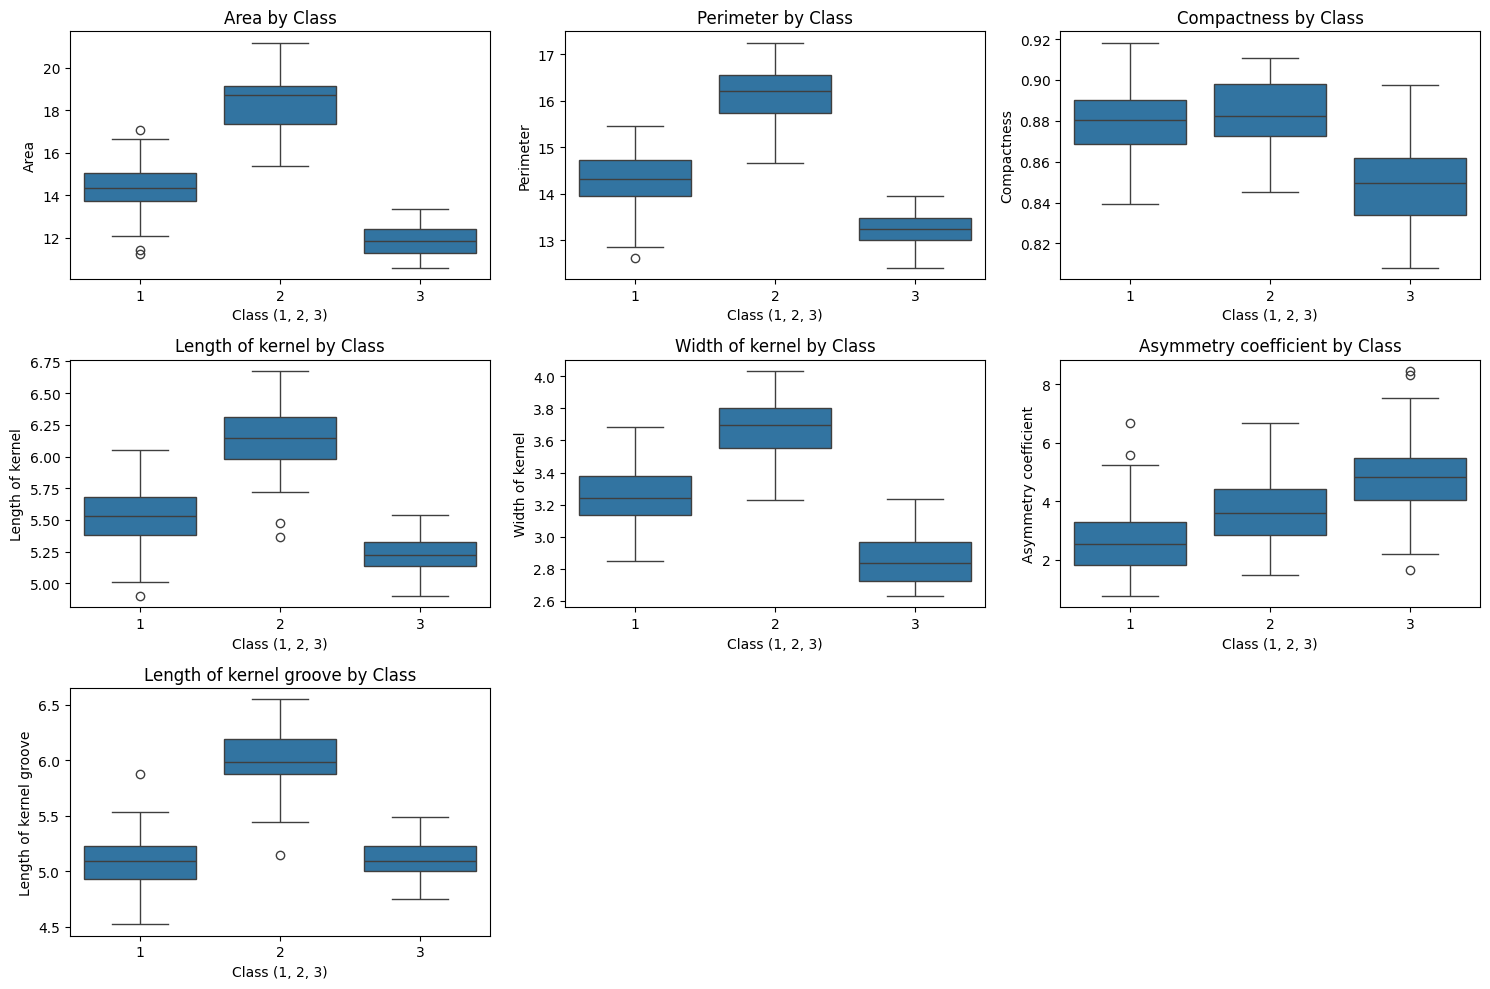

In [26]:
cleaned_df = df.drop(columns=['Unnamed: 8', 'Unnamed: 9'], errors='ignore')

print('--- Cleaned Dataset Summary ---')
display(cleaned_df.describe())

plt.figure(figsize=(15, 10))
features = cleaned_df.columns[:-1]
for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x='Class (1, 2, 3)', y=feature, data=cleaned_df)
    plt.title(f'{feature} by Class')

plt.tight_layout()
plt.show()

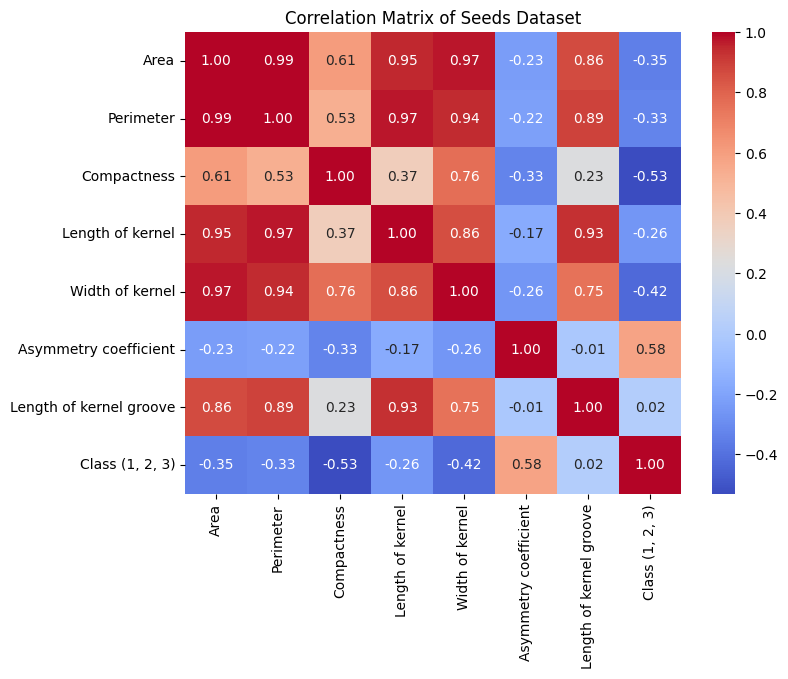

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(cleaned_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Seeds Dataset')
plt.show()

In [28]:
X = cleaned_df.drop(columns=['Class (1, 2, 3)'])
y = cleaned_df['Class (1, 2, 3)']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print('--- Scaled Features Summary (First 5 Rows) ---')
display(X_scaled_df.head())

--- Scaled Features Summary (First 5 Rows) ---


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove
0,0.142098,0.215462,0.000061,0.304218,0.141702,-0.986152,-0.383577
1,0.011188,0.008224,0.428515,-0.168625,0.197432,-1.788166,-0.922013
2,-0.192067,-0.360201,1.442383,-0.763637,0.208048,-0.667479,-1.189192
3,-0.347091,-0.475333,1.039381,-0.688978,0.319508,-0.960818,-1.229983
4,0.445257,0.330595,1.374509,0.066666,0.805159,-1.563495,-0.475356


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_df,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('--- Data Split Summary ---')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

--- Data Split Summary ---
X_train shape: (168, 7)
X_test shape: (42, 7)
y_train shape: (168,)
y_test shape: (42,)


In [30]:
y_train_zero_indexed = y_train - 1
y_test_zero_indexed = y_test - 1

model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train_zero_indexed,
    epochs=120,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.1716 - loss: 1.2277 - val_accuracy: 0.2941 - val_loss: 1.1683
Epoch 2/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2761 - loss: 1.1273 - val_accuracy: 0.3824 - val_loss: 1.0754
Epoch 3/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3209 - loss: 1.0546 - val_accuracy: 0.4412 - val_loss: 0.9914
Epoch 4/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3806 - loss: 0.9920 - val_accuracy: 0.5000 - val_loss: 0.9158
Epoch 5/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5299 - loss: 0.9417 - val_accuracy: 0.6176 - val_loss: 0.8532
Epoch 6/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6045 - loss: 0.8977 - val_accuracy: 0.6765 - val_loss: 0.8001
Epoch 7/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6343 - loss: 0.8594 - val_accuracy: 0.7353 - val_loss: 0.7539
Epoch 8/120
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7090 - loss: 0.8247 - val_accuracy: 0.7647 - val_loss:

In [31]:
test_loss, test_accuracy = model.evaluate(X_test, y_test_zero_indexed, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print('\n--- Classification Report ---')
print(classification_report(y_test_zero_indexed, y_pred, target_names=['Class 1', 'Class 2', 'Class 3']))

Test Loss: 0.3461
Test Accuracy: 0.8571
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

--- Classification Report ---
              precision    recall  f1-score   support

     Class 1       1.00      0.57      0.73        14
     Class 2       0.82      1.00      0.90        14
     Class 3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



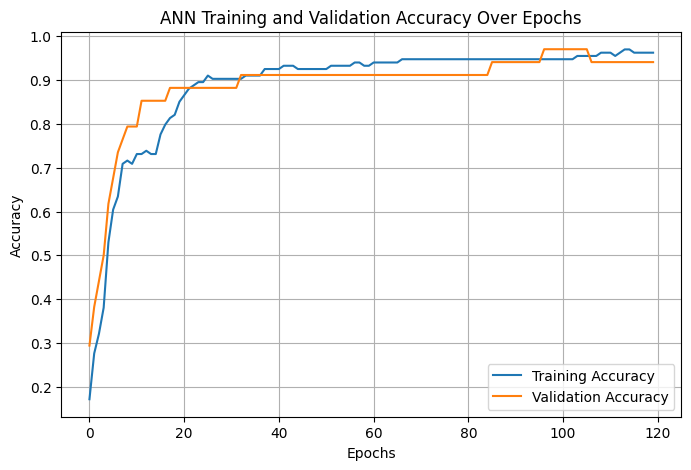

In [32]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ANN Training and Validation Accuracy Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

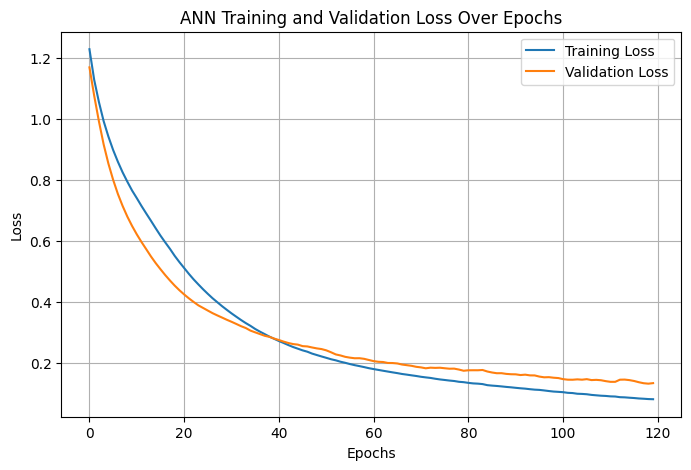

In [33]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('ANN Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
test_loss, test_accuracy = model.evaluate(X_test, y_test_zero_indexed, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

Test Loss: 0.3461
Test Accuracy: 0.8571


In [35]:
y_prob = model.predict(X_test)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
[[9.7392100e-01 6.7017629e-04 2.5408756e-02]
 [4.3628518e-02 9.9238423e-06 9.5636159e-01]
 [3.8327086e-01 5.0091320e-01 1.1581592e-01]
 [3.1379712e-04 9.8719548e-09 9.9968624e-01]
 [2.8087618e-04 9.9919683e-01 5.2228593e-04]]


In [36]:
y_pred = np.argmax(y_prob, axis=1)
print("Predicted encoded classes : ")
print(y_pred[:5])

Predicted encoded classes : 
[0 2 1 2 1]


In [37]:
y_pred_original = y_pred +1
y_test_original = y_test.values
print("Predicted classes : ")
print(y_pred_original[:10])
print("Actual classes : ")
print(y_test_original[:10])

Predicted classes : 
[1 3 2 3 2 3 2 2 2 2]
Actual classes : 
[1 3 2 3 2 3 2 1 2 2]


In [38]:
comparison = pd.DataFrame({'Actual': y_test_original, 'Predicted': y_pred_original})
print(comparison.head)

<bound method NDFrame.head of     Actual  Predicted
0        1          1
1        3          3
2        2          2
3        3          3
4        2          2
5        3          3
6        2          2
7        1          2
8        2          2
9        2          2
10       1          3
11       3          3
12       2          2
13       2          2
14       3          3
15       1          1
16       3          3
17       1          1
18       3          3
19       1          2
20       1          1
21       3          3
22       2          2
23       1          3
24       2          2
25       1          1
26       1          3
27       1          1
28       3          3
29       1          1
30       3          3
31       2          2
32       1          1
33       3          3
34       3          3
35       2          2
36       2          2
37       2          2
38       3          3
39       1          2
40       3          3
41       2          2>


In [39]:
from numpy.random.mtrand import f
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy:", accuracy)

precision = precision_score(y_test_original, y_pred_original, average='weighted')
print("Precision:", precision)

recall = recall_score(y_test_original, y_pred_original, average='weighted')
print("Recall:", recall)

f1 = f1_score(y_test_original, y_pred_original, average='weighted')
print("F1 Score:", f1)

Accuracy: 0.8571428571428571
Precision: 0.8823529411764707
Recall: 0.8571428571428571
F1 Score: 0.8445747800586509


In [40]:
metrics = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
                       'Value': [accuracy, precision, recall, f1]})
print(metrics)

      Metric     Value
0   Accuracy  0.857143
1  Precision  0.882353
2     Recall  0.857143
3   F1 Score  0.844575


In [41]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.57      0.73        14
           2       0.82      1.00      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



In [42]:
cm = confusion_matrix(y_test_original, y_pred_original)
print(cm)

[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]


Text(70.72222222222221, 0.5, 'Actual')

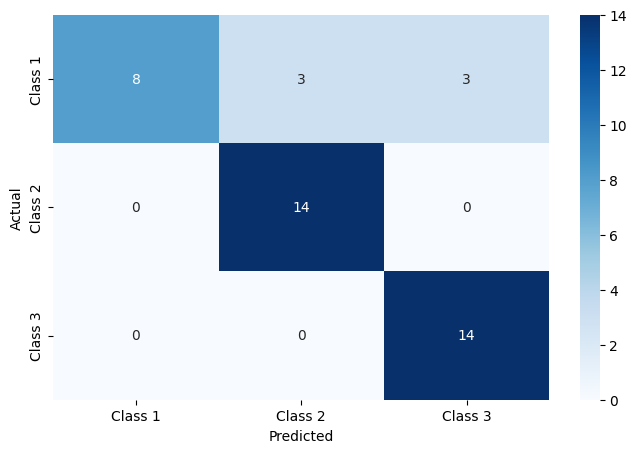

In [43]:
plt.figure(figsize=(8,5))
sns.heatmap(cm,annot=True, fmt='d', cmap='Blues', xticklabels=['Class 1', 'Class 2', 'Class 3'], yticklabels=['Class 1', 'Class 2', 'Class 3'])
plt.xlabel('Predicted')
plt.ylabel('Actual')